In [1]:
import os
from pathlib import Path
import pandas as pd

data_dir = Path('data_prepaired')
detection_datasets = []

for dataset_dir in data_dir.iterdir():
    if dataset_dir.is_dir():
        detection_datasets.append(dataset_dir.name)

print(f"Datasets for training: {detection_datasets}")

Datasets for training: ['cigar.v2i.yolo26', 'smoking.v1-smoker1.yolo26', 'project11.v1i.yolo26', 'VNTU_Object_Detection_YOLO8S.v8i.yolo26', 'CigDet_dataset', 'data_kaggle_smoke_eat_drink_phone', 'smokingProjec.v1i.yolo26', 'cigarette smokers.v5-rsd.yolo26', 'smoking26.v1i.yolo26', 'Smoking Detection.v5i.yolo26', 'iuhgiu786.v1i.yolo26', 'Smoking v2.v1i.yolo26', 'Smoking detection.v2i.yolo26', 'sigara deneme.v2i.yolo26', 'augmented.v1i.yolo26', 'Cigarette Vape Detection.v14i.yolo26']


In [2]:
import torch

In [3]:
print("GPU name:", torch.cuda.get_device_name(0))

GPU name: Tesla V100-SXM2-32GB


In [4]:
image_extensions = {'.jpg', '.jpeg', '.png', '.bmp', '.tiff', '.tif', '.webp', '.gif'}

rows = []
def get_pair_type(path):
    if 'train' in path:
        return 'train'
    if 'val' in path:
        return 'valid'
    if 'test' in path:
        return 'test'
    return 'unk'


for dataset_name in detection_datasets:
    dataset_path = data_dir / dataset_name

    txt_files = list(dataset_path.rglob('*.txt'))
    image_files = []
    for ext in image_extensions:
        image_files.extend(dataset_path.rglob(f'*{ext}'))

    image_dict = {img.stem: img for img in image_files}

    for txt_file in txt_files:
        txt_stem = txt_file.stem

        if txt_stem in image_dict:
            img_file = image_dict[txt_stem]
            rows.append({
                'dataset': dataset_name,
                'txt_path': str(txt_file),
                'image_path': str(img_file),
                'image_dir': get_pair_type(str(img_file))
            })

df = pd.DataFrame(rows)
print(f"Total matched pairs: {len(df)}")
df.head()

Total matched pairs: 10704


,dataset,txt_path,image_path,image_dir
0,cigar.v2i.yolo26,data_prepaired/cigar.v2i.yolo26/test/labels/sm...,data_prepaired/cigar.v2i.yolo26/test/images/sm...,test
1,cigar.v2i.yolo26,data_prepaired/cigar.v2i.yolo26/test/labels/rk...,data_prepaired/cigar.v2i.yolo26/test/images/rk...,test
2,cigar.v2i.yolo26,data_prepaired/cigar.v2i.yolo26/test/labels/sm...,data_prepaired/cigar.v2i.yolo26/test/images/sm...,test
3,cigar.v2i.yolo26,data_prepaired/cigar.v2i.yolo26/test/labels/sm...,data_prepaired/cigar.v2i.yolo26/test/images/sm...,test
4,cigar.v2i.yolo26,data_prepaired/cigar.v2i.yolo26/test/labels/sm...,data_prepaired/cigar.v2i.yolo26/test/images/sm...,test


In [5]:
result = (
    df
    .groupby(["dataset", "image_dir"])
    .size()
    .unstack(fill_value=0)
    .assign(total=lambda x: x.sum(axis=1))
    .reset_index()
)
result

image_dir,dataset,test,train,valid,total
0,CigDet_dataset,2,3,0,5
1,Cigarette Vape Detection.v14i.yolo26,152,2751,286,3189
2,Smoking Detection.v5i.yolo26,220,1497,81,1798
3,Smoking detection.v2i.yolo26,0,61,5,66
4,Smoking v2.v1i.yolo26,1,15,0,16
5,VNTU_Object_Detection_YOLO8S.v8i.yolo26,21,408,101,530
6,augmented.v1i.yolo26,63,419,119,601
7,cigar.v2i.yolo26,12,190,14,216
8,cigarette smokers.v5-rsd.yolo26,115,798,111,1024
9,data_kaggle_smoke_eat_drink_phone,104,760,213,1077


In [6]:
import matplotlib.pyplot as plt
from PIL import Image
import matplotlib.patches as patches

def visualize_yolo_sample(row, class_names=None):
    img = Image.open(row.image_path).convert("RGB")
    w, h = img.size
    img_area = w * h

    fig, ax = plt.subplots(1, figsize=(10, 10))
    ax.imshow(img)

    with open(row.txt_path) as f:
        for i, line in enumerate(f, 1):
            cls, cx, cy, bw, bh = map(float, line.strip().split())
            x = (cx - bw / 2) * w
            y = (cy - bh / 2) * h
            bw_px = bw * w
            bh_px = bh * h

            box_area_px = bw_px * bh_px
            box_area_rel = box_area_px / img_area

            print(
                f"box {i}: "
                f"class={int(cls)} "
                f"area_px={box_area_px:.1f} "
                f"area_rel={box_area_rel:.4f}"
            )

            rect = patches.Rectangle(
                (x, y), bw_px, bh_px,
                linewidth=2, edgecolor="red", facecolor="none"
            )
            ax.add_patch(rect)

            label = class_names[int(cls)] if class_names else str(int(cls))
            ax.text(x, y - 5, label, color="red", fontsize=12, backgroundcolor="white")

    ax.axis("off")
    plt.show()

box 1: class=0 area_px=560.0 area_rel=0.0014


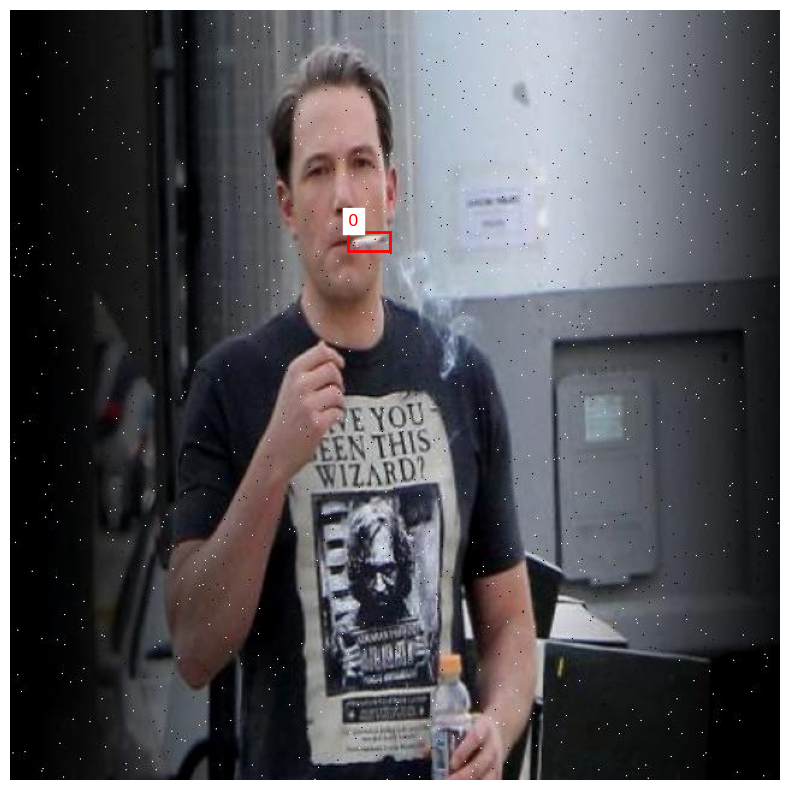

In [7]:
visualize_yolo_sample(df.iloc[10100])

In [8]:
from collections import defaultdict

def dataset_to_classes(df):
    result = defaultdict(set)

    for _, row in df.iterrows():
        with open(row.txt_path) as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) < 1:
                    continue
                cls = int(float(parts[0]))
                result[row.dataset].add(cls)

    return {k: sorted(v) for k, v in result.items()}

In [9]:
dataset_classes = dataset_to_classes(df)
dataset_classes

{'cigar.v2i.yolo26': [0],
 'smoking.v1-smoker1.yolo26': [0],
 'project11.v1i.yolo26': [0],
 'VNTU_Object_Detection_YOLO8S.v8i.yolo26': [0],
 'CigDet_dataset': [0],
 'data_kaggle_smoke_eat_drink_phone': [0],
 'smokingProjec.v1i.yolo26': [0],
 'cigarette smokers.v5-rsd.yolo26': [0],
 'smoking26.v1i.yolo26': [0],
 'Smoking Detection.v5i.yolo26': [0],
 'iuhgiu786.v1i.yolo26': [0],
 'Smoking v2.v1i.yolo26': [0],
 'Smoking detection.v2i.yolo26': [0],
 'sigara deneme.v2i.yolo26': [0],
 'augmented.v1i.yolo26': [0],
 'Cigarette Vape Detection.v14i.yolo26': [0]}

## Split and concat

In [10]:
train_df = df[df['image_dir'].isin(['train', 'training', 'Train'])].reset_index(drop=True)
val_df = df[df['image_dir'].isin(['val', 'valid', 'validation', 'Val'])].reset_index(drop=True)
test_df = df[df['image_dir'].isin(['test', 'testing', 'Test'])].reset_index(drop=True)

print(f"Train: {len(train_df)}, Val: {len(val_df)}, Test: {len(test_df)}")
print(f"\nUnique image_dir values: {df['image_dir'].unique()}")

Train: 8544, Val: 1240, Test: 920

Unique image_dir values: ['test' 'train' 'valid']


In [11]:
import torch
import torchvision
from torchvision.models.detection import fasterrcnn_resnet50_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T
from PIL import Image
import numpy as np

In [12]:
class DetectionDataset(Dataset):
    def __init__(self, dataframe, transforms=None):
        self.df = dataframe.reset_index(drop=True)
        self.transforms = transforms

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        img = Image.open(row['image_path']).convert('RGB')

        boxes = []
        labels = []

        with open(row['txt_path'], 'r') as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) >= 5:
                    class_id = int(parts[0])
                    x_center, y_center, width, height = map(float, parts[1:5])

                    img_width, img_height = img.size

                    x_min = (x_center - width / 2) * img_width
                    y_min = (y_center - height / 2) * img_height
                    x_max = (x_center + width / 2) * img_width
                    y_max = (y_center + height / 2) * img_height

                    boxes.append([x_min, y_min, x_max, y_max])
                    labels.append(class_id + 1)

        boxes = torch.as_tensor(boxes, dtype=torch.float32)
        labels = torch.as_tensor(labels, dtype=torch.int64)

        target = {}
        target['boxes'] = boxes
        target['labels'] = labels
        target['image_id'] = torch.tensor([idx])

        if self.transforms:
            img = self.transforms(img)

        return img, target

def get_transform(train):
    transforms = []
    transforms.append(T.ToTensor())
    if train:
        transforms.append(T.RandomHorizontalFlip(0.5))
    return T.Compose(transforms)

In [13]:
train_dataset = DetectionDataset(train_df, get_transform(train=True))
val_dataset = DetectionDataset(val_df, get_transform(train=False))
test_dataset = DetectionDataset(test_df, get_transform(train=False))

print(f"Datasets created: train={len(train_dataset)}, val={len(val_dataset)}, test={len(test_dataset)}")

Datasets created: train=8544, val=1240, test=920


In [14]:
def collate_fn(batch):
    return tuple(zip(*batch))

In [15]:
batch_size = 32
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, collate_fn=collate_fn)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, collate_fn=collate_fn)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, collate_fn=collate_fn)

print("DataLoaders created")

DataLoaders created


In [16]:
device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')
print(f"Using device: {device}")

Using device: cuda


In [22]:
model = fasterrcnn_resnet50_fpn(weights='DEFAULT')

num_classes = 2
in_features = model.roi_heads.box_predictor.cls_score.in_features
model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes)
backbone_params = []
head_params = []

for name, param in model.named_parameters():
    if not param.requires_grad:
        continue
    if "roi_heads.box_predictor" in name:
        head_params.append(param)
    else:
        backbone_params.append(param)


model.to(device)

params = [p for p in model.parameters() if p.requires_grad]
optimizer = torch.optim.AdamW(
    [
        {"params": backbone_params, "lr": 1e-4},
        {"params": head_params, "lr": 3e-4},
    ],
    weight_decay=1e-4,
    betas=(0.9, 0.999),
)

lr_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=num_epochs,
    eta_min=1e-6
)


print("Faster R-CNN model initialized")

Faster R-CNN model initialized


In [24]:
from tqdm import tqdm
import os

save_dir = Path('checkpoints_frcnn_adamw')
save_dir.mkdir(exist_ok=True)

In [25]:
num_epochs = 20


train_losses = []
val_losses = []

for epoch in range(num_epochs):
    torch.cuda.empty_cache()
    model.train()
    epoch_loss = 0

    pbar = tqdm(train_loader, desc=f'Epoch {epoch+1}/{num_epochs}')
    for images, targets in pbar:
        images = list(image.to(device) for image in images)
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]

        loss_dict = model(images, targets)
        losses = sum(loss for loss in loss_dict.values())

        optimizer.zero_grad()
        losses.backward()
        optimizer.step()

        epoch_loss += losses.item()
        pbar.set_postfix({'loss': losses.item()})
        torch.cuda.empty_cache()

    avg_train_loss = epoch_loss / len(train_loader)
    train_losses.append(avg_train_loss)

    model.eval()
    val_loss = 0
    with torch.no_grad():
        for images, targets in val_loader:
            images = list(image.to(device) for image in images)
            targets = [{k: v.to(device) for k, v in t.items()} for t in targets]

            model.train()
            loss_dict = model(images, targets)
            losses = sum(loss for loss in loss_dict.values())
            val_loss += losses.item()
            model.eval()

    avg_val_loss = val_loss / len(val_loader)
    val_losses.append(avg_val_loss)

    lr_scheduler.step()

    print(f'Epoch {epoch+1}: Train Loss = {avg_train_loss:.4f}, Val Loss = {avg_val_loss:.4f}')

    if (epoch + 1) % 5 == 0:
        checkpoint_path = save_dir / f'frcnn_epoch_{epoch+1}.pth'
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'train_loss': avg_train_loss,
            'val_loss': avg_val_loss,
        }, checkpoint_path)
        print(f'Checkpoint saved: {checkpoint_path}')

final_model_path = save_dir / 'frcnn_final.pth'
torch.save(model.state_dict(), final_model_path)
print(f'Final model saved: {final_model_path}')

Epoch 1/20: 100%|██████████| 267/267 [04:50<00:00,  1.09s/it, loss=0.205]


Epoch 1: Train Loss = 0.2539, Val Loss = 0.2159


Epoch 2/20: 100%|██████████| 267/267 [04:50<00:00,  1.09s/it, loss=0.236]


Epoch 2: Train Loss = 0.2111, Val Loss = 0.2033


Epoch 3/20: 100%|██████████| 267/267 [04:49<00:00,  1.08s/it, loss=0.207]


...

Epoch 18: Train Loss = 0.0573, Val Loss = 0.2489


Epoch 19/20: 100%|██████████| 267/267 [04:49<00:00,  1.08s/it, loss=0.084] 


Epoch 19: Train Loss = 0.0542, Val Loss = 0.2550


Epoch 20/20: 100%|██████████| 267/267 [04:50<00:00,  1.09s/it, loss=0.0328]


Epoch 20: Train Loss = 0.0516, Val Loss = 0.2548
Checkpoint saved: checkpoints_frcnn_adamw/frcnn_epoch_20.pth
Final model saved: checkpoints_frcnn_adamw/frcnn_final.pth


In [26]:
torch.cuda.empty_cache()

In [27]:
t = torch.cuda.get_device_properties(0).total_memory
r = torch.cuda.memory_reserved(0)
a = torch.cuda.memory_allocated(0)
f = r-a
t, r, a, f

(84974239744, 17741905920, 16851755520, 890150400)

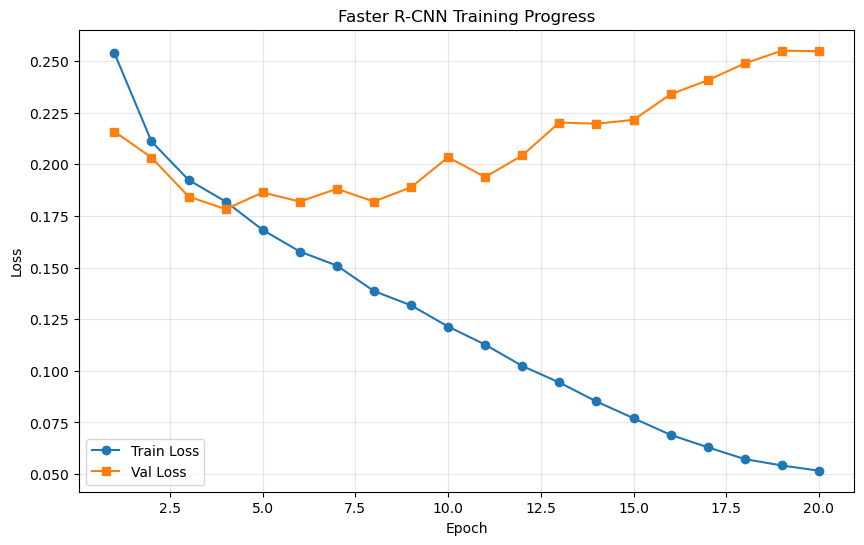

In [28]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.plot(range(1, num_epochs+1), train_losses, label='Train Loss', marker='o')
plt.plot(range(1, num_epochs+1), val_losses, label='Val Loss', marker='s')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Faster R-CNN Training Progress')
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig('frcnn_training_curves.png', dpi=150, bbox_inches='tight')
plt.show()

In [29]:
from torchvision.ops import box_iou

def evaluate_model(model, data_loader, device, iou_threshold=0.5):
    model.eval()

    all_precisions = []
    all_recalls = []
    all_aps = []

    with torch.no_grad():
        for images, targets in tqdm(data_loader, desc='Evaluating'):
            images = list(img.to(device) for img in images)

            outputs = model(images)

            for output, target in zip(outputs, targets):
                pred_boxes = output['boxes'].cpu()
                pred_scores = output['scores'].cpu()
                pred_labels = output['labels'].cpu()

                gt_boxes = target['boxes'].cpu()
                gt_labels = target['labels'].cpu()

                if len(pred_boxes) == 0 or len(gt_boxes) == 0:
                    continue

                score_threshold = 0.5
                mask = pred_scores > score_threshold
                pred_boxes = pred_boxes[mask]
                pred_labels = pred_labels[mask]
                pred_scores = pred_scores[mask]

                if len(pred_boxes) == 0:
                    all_precisions.append(0.0)
                    all_recalls.append(0.0)
                    continue

                ious = box_iou(pred_boxes, gt_boxes)

                matched_gt = set()
                tp = 0

                sorted_indices = torch.argsort(pred_scores, descending=True)

                for idx in sorted_indices:
                    max_iou, max_gt_idx = ious[idx].max(0)

                    if max_iou >= iou_threshold and max_gt_idx.item() not in matched_gt:
                        if pred_labels[idx] == gt_labels[max_gt_idx]:
                            tp += 1
                            matched_gt.add(max_gt_idx.item())

                precision = tp / len(pred_boxes) if len(pred_boxes) > 0 else 0
                recall = tp / len(gt_boxes) if len(gt_boxes) > 0 else 0

                all_precisions.append(precision)
                all_recalls.append(recall)

    avg_precision = np.mean(all_precisions)
    avg_recall = np.mean(all_recalls)
    f1 = 2 * avg_precision * avg_recall / (avg_precision + avg_recall) if (avg_precision + avg_recall) > 0 else 0

    return {
        'precision': avg_precision,
        'recall': avg_recall,
        'f1': f1,
        'mAP50': avg_precision
    }

print("Evaluating on validation set...")
val_metrics = evaluate_model(model, val_loader, device)
print(f"\nValidation Metrics:")
print(f"Precision: {val_metrics['precision']:.4f}")
print(f"Recall: {val_metrics['recall']:.4f}")
print(f"F1: {val_metrics['f1']:.4f}")
print(f"mAP@0.5: {val_metrics['mAP50']:.4f}")

print("\nEvaluating on test set...")
test_metrics = evaluate_model(model, test_loader, device)
print(f"\nTest Metrics:")
print(f"Precision: {test_metrics['precision']:.4f}")
print(f"Recall: {test_metrics['recall']:.4f}")
print(f"F1: {test_metrics['f1']:.4f}")
print(f"mAP@0.5: {test_metrics['mAP50']:.4f}")

Evaluating on validation set...


Evaluating: 100%|██████████| 39/39 [00:21<00:00,  1.81it/s]



Validation Metrics:
Precision: 0.8298
Recall: 0.8175
F1: 0.8236
mAP@0.5: 0.8298

Evaluating on test set...


Evaluating: 100%|██████████| 29/29 [00:33<00:00,  1.14s/it]


Test Metrics:
Precision: 0.7307
Recall: 0.6947
F1: 0.7123
mAP@0.5: 0.7307


In [30]:
dataset_metrics = []

for dataset_name in df['dataset'].unique():
    dataset_samples = df[df['dataset'] == dataset_name]

    val_samples = dataset_samples[dataset_samples['image_dir'].isin(['val', 'valid', 'validation', 'Val'])]
    test_samples = dataset_samples[dataset_samples['image_dir'].isin(['test', 'testing', 'Test'])]

    print(f"\n{'='*60}")
    print(f"Dataset: {dataset_name}")
    print(f"Val samples: {len(val_samples)}, Test samples: {len(test_samples)}")

    for split_name, split_samples in [('val', val_samples), ('test', test_samples)]:
        if len(split_samples) == 0:
            continue

        split_dataset = DetectionDataset(split_samples, get_transform(train=False))
        split_loader = DataLoader(split_dataset, batch_size=4, shuffle=False, num_workers=4, collate_fn=collate_fn)

        metrics = evaluate_model(model, split_loader, device)

        dataset_metrics.append({
            'dataset': dataset_name,
            'split': split_name,
            'samples': len(split_samples),
            'precision': metrics['precision'],
            'recall': metrics['recall'],
            'f1': metrics['f1'],
            'mAP50': metrics['mAP50']
        })

        print(f"{split_name.upper()} - Precision: {metrics['precision']:.4f}, Recall: {metrics['recall']:.4f}, F1: {metrics['f1']:.4f}, mAP@0.5: {metrics['mAP50']:.4f}")

frcnn_metrics_df = pd.DataFrame(dataset_metrics)
frcnn_metrics_df.to_csv('frcnn_per_dataset_metrics.csv', index=False)
print("\nMetrics saved to frcnn_per_dataset_metrics.csv")
frcnn_metrics_df


Dataset: cigar.v2i.yolo26
Val samples: 14, Test samples: 12


Evaluating: 100%|██████████| 4/4 [00:00<00:00,  4.45it/s]


VAL - Precision: 0.8333, Recall: 0.8333, F1: 0.8333, mAP@0.5: 0.8333


Evaluating: 100%|██████████| 3/3 [00:00<00:00,  4.94it/s]


TEST - Precision: 0.6818, Recall: 0.7273, F1: 0.7038, mAP@0.5: 0.6818

Dataset: smoking.v1-smoker1.yolo26
Val samples: 115, Test samples: 119


...

Evaluating: 100%|██████████| 72/72 [00:06<00:00, 11.57it/s]


VAL - Precision: 0.7082, Recall: 0.6967, F1: 0.7024, mAP@0.5: 0.7082


Evaluating: 100%|██████████| 38/38 [00:03<00:00, 10.93it/s]


TEST - Precision: 0.7812, Recall: 0.7646, F1: 0.7728, mAP@0.5: 0.7812

Metrics saved to frcnn_per_dataset_metrics.csv


,dataset,split,samples,precision,recall,f1,mAP50
0,cigar.v2i.yolo26,val,14,0.833333,0.833333,0.833333,0.833333
1,cigar.v2i.yolo26,test,12,0.681818,0.727273,0.703812,0.681818
2,smoking.v1-smoker1.yolo26,val,115,0.653930,0.569579,0.608847,0.653930
3,smoking.v1-smoker1.yolo26,test,119,0.922005,0.934574,0.928247,0.922005
4,project11.v1i.yolo26,val,5,0.717857,0.717857,0.717857,0.717857
5,project11.v1i.yolo26,test,6,0.041667,0.041667,0.041667,0.041667
6,VNTU_Object_Detection_YOLO8S.v8i.yolo26,val,101,0.686047,0.680233,0.683127,0.686047
7,VNTU_Object_Detection_YOLO8S.v8i.yolo26,test,21,0.437500,0.500000,0.466667,0.437500
8,CigDet_dataset,test,2,0.500000,1.000000,0.666667,0.500000
9,data_kaggle_smoke_eat_drink_phone,val,213,0.471631,0.460106,0.465798,0.471631


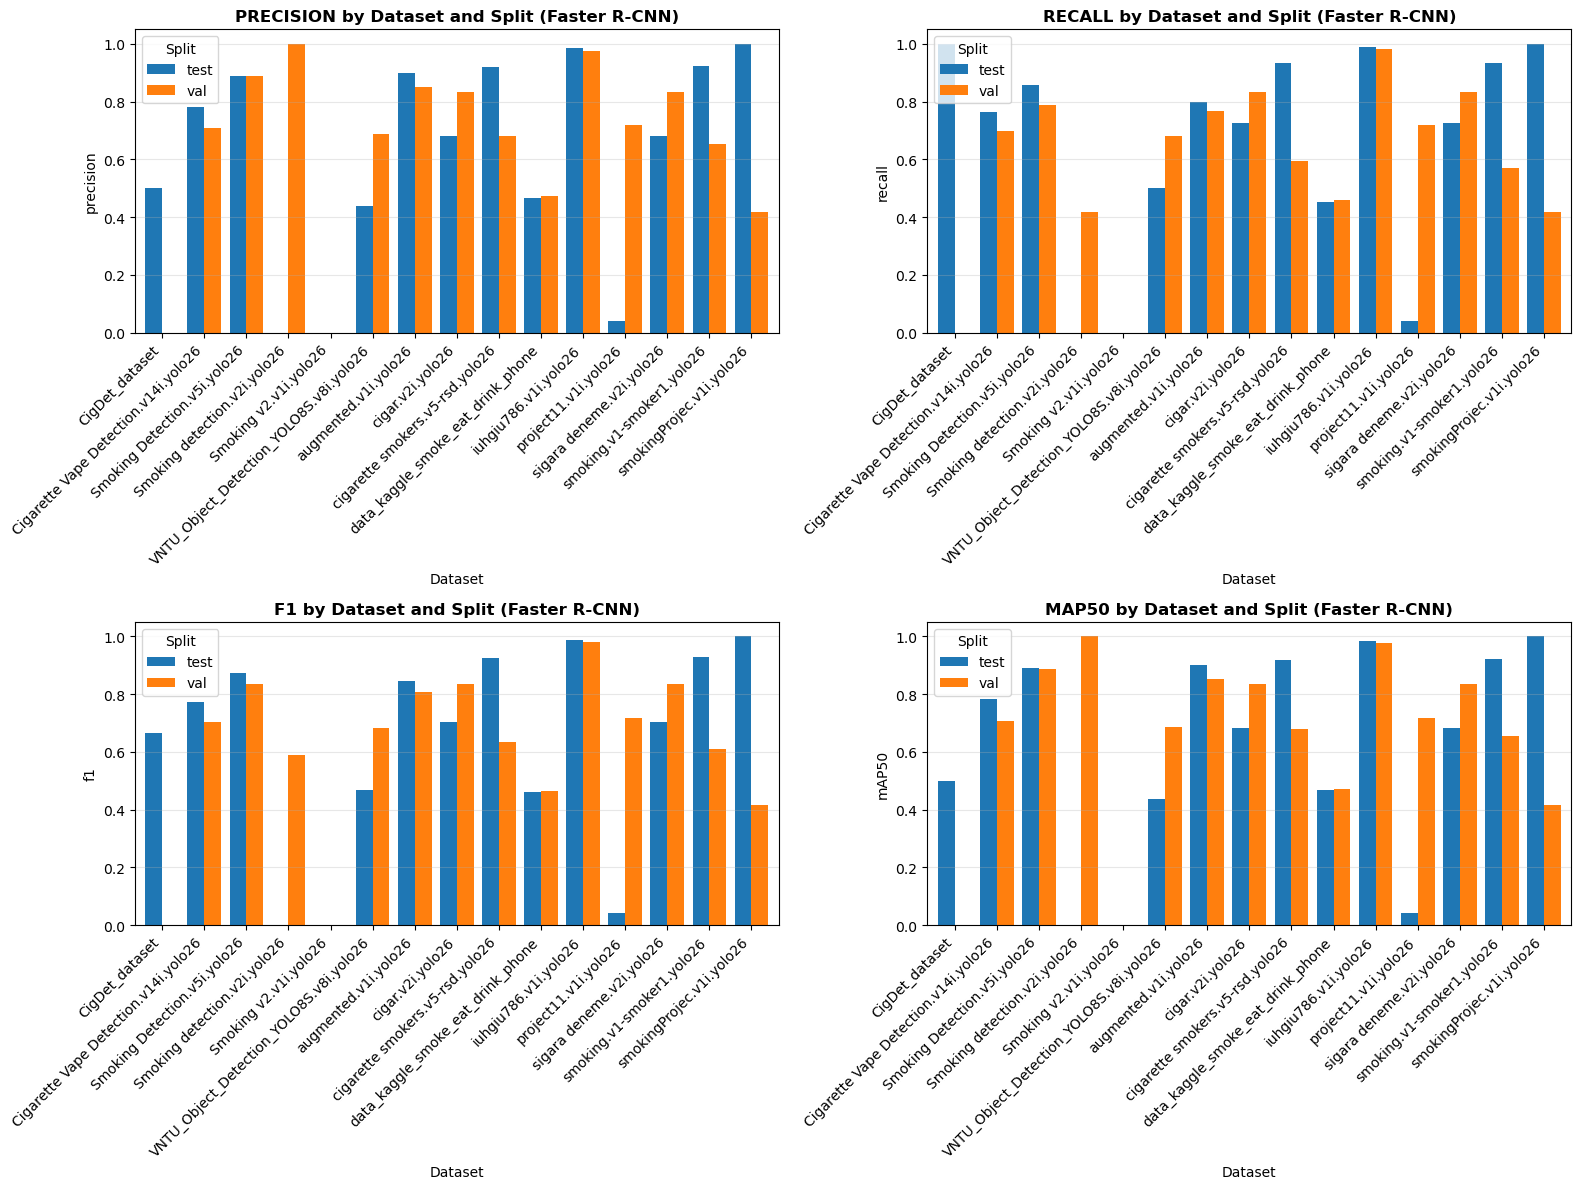

In [31]:
import seaborn as sns

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

for idx, metric in enumerate(['precision', 'recall', 'f1', 'mAP50']):
    ax = axes[idx // 2, idx % 2]

    pivot_data = frcnn_metrics_df.pivot(index='dataset', columns='split', values=metric)
    pivot_data.plot(kind='bar', ax=ax, width=0.8)

    ax.set_title(f'{metric.upper()} by Dataset and Split (Faster R-CNN)', fontsize=12, fontweight='bold')
    ax.set_xlabel('Dataset', fontsize=10)
    ax.set_ylabel(metric, fontsize=10)
    ax.legend(title='Split')
    ax.grid(axis='y', alpha=0.3)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')

plt.tight_layout()
plt.savefig('frcnn_per_dataset_metrics.png', dpi=150, bbox_inches='tight')
plt.show()

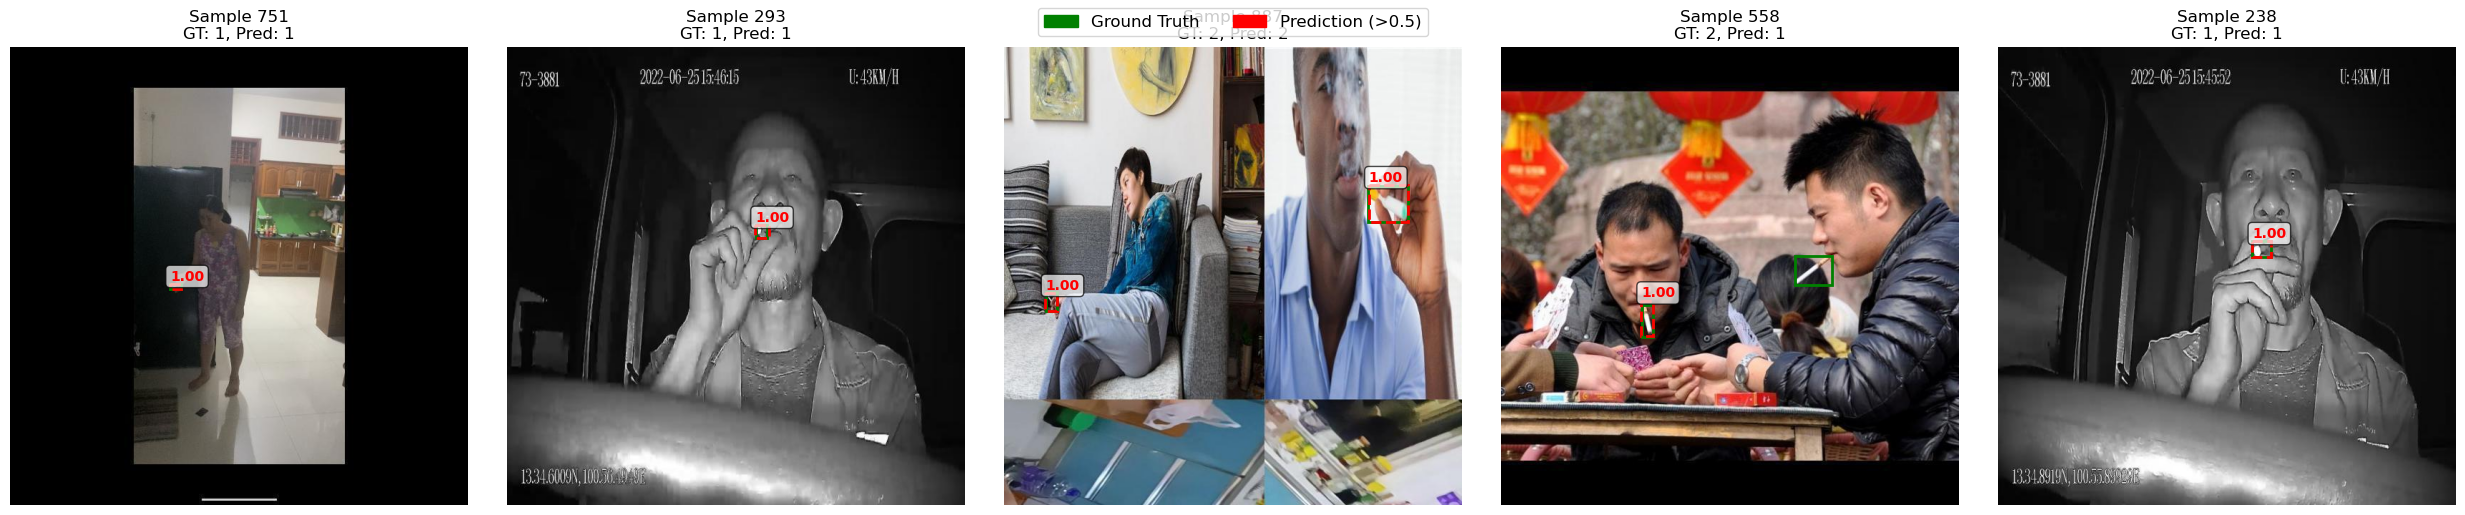

In [32]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import random

model.eval()

random_indices = random.sample(range(len(val_dataset)), min(5, len(val_dataset)))

fig, axes = plt.subplots(1, 5, figsize=(25, 5))

with torch.no_grad():
    for idx, sample_idx in enumerate(random_indices):
        image, target = val_dataset[sample_idx]

        image_tensor = image.unsqueeze(0).to(device)
        prediction = model(image_tensor)[0]

        image_np = image.permute(1, 2, 0).cpu().numpy()

        ax = axes[idx]
        ax.imshow(image_np)

        gt_boxes = target['boxes'].cpu().numpy()
        for box in gt_boxes:
            x_min, y_min, x_max, y_max = box
            rect = patches.Rectangle((x_min, y_min), x_max - x_min, y_max - y_min,
                                     linewidth=2, edgecolor='green', facecolor='none', label='GT')
            ax.add_patch(rect)

        pred_boxes = prediction['boxes'].cpu().numpy()
        pred_scores = prediction['scores'].cpu().numpy()

        for box, score in zip(pred_boxes, pred_scores):
            if score > 0.5:
                x_min, y_min, x_max, y_max = box
                rect = patches.Rectangle((x_min, y_min), x_max - x_min, y_max - y_min,
                                         linewidth=2, edgecolor='red', facecolor='none', linestyle='--')
                ax.add_patch(rect)
                ax.text(x_min, y_min - 5, f'{score:.2f}',
                       color='red', fontsize=10, weight='bold',
                       bbox=dict(boxstyle='round', facecolor='white', alpha=0.7))

        ax.set_title(f'Sample {sample_idx}\nGT: {len(gt_boxes)}, Pred: {(pred_scores > 0.5).sum()}')
        ax.axis('off')

green_patch = patches.Patch(color='green', label='Ground Truth')
red_patch = patches.Patch(color='red', label='Prediction (>0.5)')
fig.legend(handles=[green_patch, red_patch], loc='upper center', ncol=2, fontsize=12)

plt.tight_layout()
plt.savefig('frcnn_predictions_validation.png', dpi=150, bbox_inches='tight')
plt.show()

## YOLO26l training

In [24]:
import shutil
yolo_dir = Path('yolo_dataset')
yolo_dir.mkdir(exist_ok=True)

for split_name, split_df in [('train', train_df), ('val', val_df), ('test', test_df)]:
    images_dir = yolo_dir / split_name / 'images'
    labels_dir = yolo_dir / split_name / 'labels'
    images_dir.mkdir(parents=True, exist_ok=True)
    labels_dir.mkdir(parents=True, exist_ok=True)
    
    for idx, row in split_df.iterrows():
        img_src = Path(row['image_path'])
        txt_src = Path(row['txt_path'])
        
        img_dst = images_dir / img_src.name
        txt_dst = labels_dir / txt_src.name
        
        if not img_dst.exists():
            shutil.copy(img_src, img_dst)
        if not txt_dst.exists():
            shutil.copy(txt_src, txt_dst)
    
    print(f"{split_name}: {len(split_df)} samples copied")

train: 8544 samples copied
val: 1240 samples copied
test: 920 samples copied


In [25]:
import yaml

data_yaml = {
    'path': str(yolo_dir.absolute()),
    'train': 'train/images',
    'val': 'val/images',
    'test': 'test/images',
    'nc': 1,
    'names': ['smoking']
}

with open(yolo_dir / 'data.yaml', 'w') as f:
    yaml.dump(data_yaml, f)

print("data.yaml created")

data.yaml created


In [26]:
import ultralytics

In [20]:
from ultralytics import YOLO
import importlib
import ultralytics

importlib.reload(ultralytics)

print(f"Ultralytics version: {ultralytics.__version__}")

yolo_model = YOLO('yolo26l.pt')
print("YOLO model loaded")

Ultralytics version: 8.4.12
YOLO model loaded


In [22]:
results = yolo_model.train(
    data=str(yolo_dir / 'data.yaml'),
    epochs=50,
    imgsz=640,
    batch=16,
    device=device,
    project='runs/detect',
    name='smoking_yolo26l',
    save=True,
    save_period=5,
    plots=True,
    verbose=True,
    patience=10,
    workers=4,
    optimizer='AdamW',
    lr0=0.001,
    lrf=0.01,
    weight_decay=0.0005,
    warmup_epochs=3,
    cos_lr=True
)

engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=yolo_dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26l.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=smoking_yolo26l, nbs=64, nms=False, opset=None, optimize=False, optimizer=AdamW, overlap_mask=True, patience=10, perspective=0.0, plots=True, pose=12.0, pretrained=True, profile=False, project=runs/detect, r


curl: (7) Failed connect to github.com:443; Connection timed out


WARNING Download failure, retrying 3/3 https://github.com/ultralytics/assets/releases/download/v8.4.0/yolo26n.pt... Curl return value 7



curl: (7) Failed connect to github.com:443; Connection timed out
######################################################################## 100.0%

WARNING AMP: checks skipped. Offline and unable to download YOLO26n for AMP checks. Setting 'amp=True'. If you experience zero-mAP or NaN losses you can disable AMP with amp=False.
train: Fast image access (ping: 0.2±0.1 ms, read: 92.2±24.5 MB/s, size: 43.3 KB)



curl: (7) Failed connect to github.com:443; Connection timed out


train: Scanning yolo_dataset/train/labels... 8542 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 8542/8542 1.9Kit/s 4.6s0.1s
train: New cache created: yolo_dataset/train/labels.cache
WARNING Box and segment counts should be equal, but got len(segments) = 21, len(boxes) = 14086. To resolve this only boxes will be used and all segments will be removed. To avoid this please supply either a detect or segment dataset, not a detect-segment mixed dataset.


val: Fast image access (ping: 0.2±0.0 ms, read: 57.6±17.0 MB/s, size: 38.1 KB)
val: Scanning yolo_dataset/val/labels... 1240 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1240/1240 1.2Kit/s 1.1s0.1s
val: New cache created: yolo_dataset/val/labels.cache


Plotting labels to runs/detect/runs/detect/smoking_yolo26l/labels.jpg... 
optimizer: AdamW(lr=0.001, momentum=0.937) with parameter groups 178 weight(decay=0.0), 190 weight(decay=0.0005), 190 bias(decay=0.0)
Image sizes 640 train, 640 val
Using 4 dataloader workers
Logging results to runs/detect/runs/detect/smoking_yolo26l
Starting training for 50 epochs...

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       1/50        11G      2.477      2.684   0.007979         19        640: 100% ━━━━━━━━━━━━ 534/534 2.5it/s 3:33<0.4s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 39/39 3.4it/s 11.4s0.2s
                   all       1240       2296      0.356      0.292      0.234     0.0847

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       2/50      13.1G      2.415      2.173   0.007955         25        640: 100% ━━━━━━━━━━━━ 534/534 2.7it/s 3:18<0.4s
               


      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      41/50      17.1G      1.326     0.6176   0.003842         32        640: 100% ━━━━━━━━━━━━ 534/534 2.9it/s 3:05<0.3s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 39/39 4.4it/s 8.8s0.2s
                   all       1240       2296      0.818      0.771      0.824      0.472

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      42/50      17.2G      1.314     0.6007   0.003836         13        640: 100% ━━━━━━━━━━━━ 534/534 2.9it/s 3:02<0.3s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 39/39 4.4it/s 8.9s0.2s
                   all       1240       2296      0.824       0.77      0.828      0.475

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      43/50      17.3G        1.3      0.596   0.003839         19        640

Available PNG files in runs/detect/runs/detect/smoking_yolo26l:
  - confusion_matrix.png
  - BoxPR_curve.png
  - BoxP_curve.png
  - BoxR_curve.png
  - BoxF1_curve.png
  - results.png
  - confusion_matrix_normalized.png


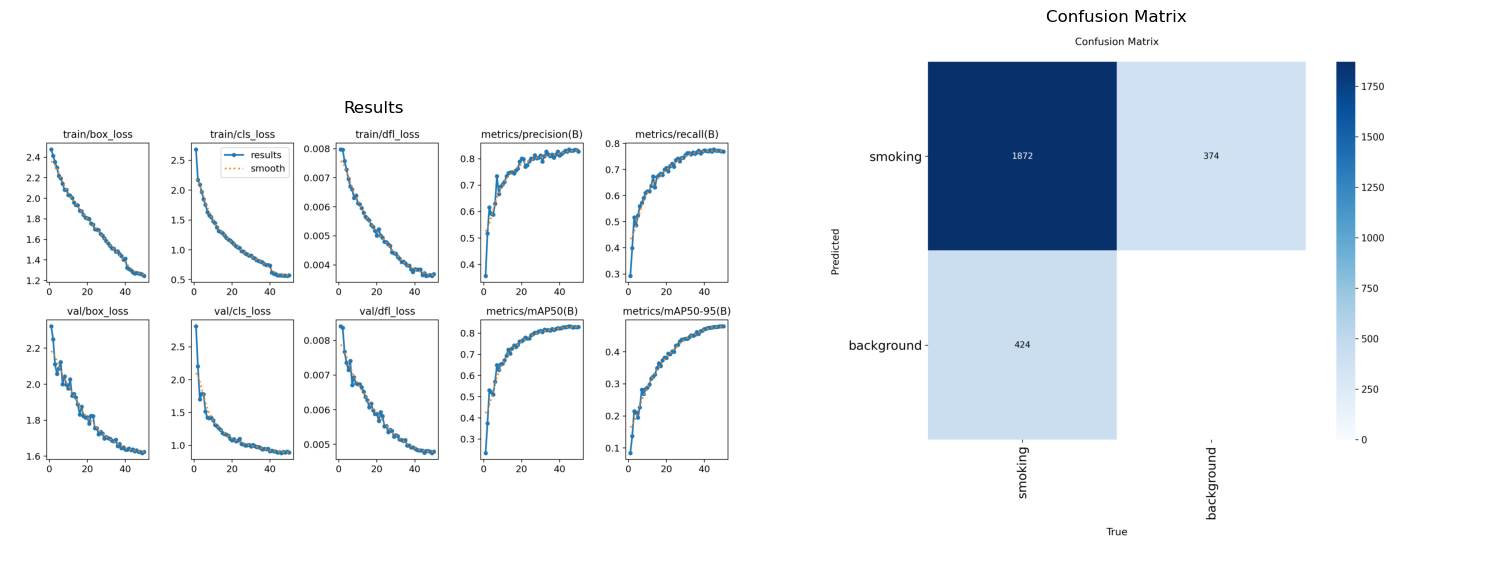

In [29]:
import matplotlib.pyplot as plt
from PIL import Image

results_dir = Path('runs/detect/runs/detect/smoking_yolo26l')

available_files = list(results_dir.glob('*.png'))
print(f"Available PNG files in {results_dir}:")
for f in available_files:
    print(f"  - {f.name}")

metrics_to_plot = ['results.png', 'confusion_matrix.png', 'F1_curve.png', 'PR_curve.png']

existing_metrics = [m for m in metrics_to_plot if (results_dir / m).exists()]

if not existing_metrics:
    print("No metric plots found. Using all available PNG files instead.")
    existing_metrics = [f.name for f in available_files[:4]]

if existing_metrics:
    n_plots = len(existing_metrics)
    n_cols = 2
    n_rows = (n_plots + 1) // 2
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 6 * n_rows))
    axes = axes.flat if n_plots > 1 else [axes]
    
    for ax, metric_file in zip(axes, existing_metrics):
        img_path = results_dir / metric_file
        img = Image.open(img_path)
        ax.imshow(img)
        ax.axis('off')
        ax.set_title(metric_file.replace('.png', '').replace('_', ' ').title())
    
    for ax in axes[len(existing_metrics):]:
        ax.axis('off')
    
    plt.tight_layout()
    plt.savefig('yolo26_training_summary.png', dpi=150, bbox_inches='tight')
    plt.show()
else:
    print("No plots available to display.")

In [27]:
from ultralytics import YOLO
import importlib
import ultralytics


best_yolo = YOLO('runs/detect/runs/detect/smoking_yolo26l/weights/best.pt')

val_metrics = best_yolo.val(
    data=str(yolo_dir / 'data.yaml'),
    split='val',
    device=device,
    save_json=True,
    plots=True
)

print("\nValidation Set Metrics:")
print(f"mAP50: {val_metrics.box.map50:.4f}")
print(f"mAP50-95: {val_metrics.box.map:.4f}")
print(f"Precision: {val_metrics.box.p[0]:.4f}")
print(f"Recall: {val_metrics.box.r[0]:.4f}")
val_f1 = 2 * val_metrics.box.p[0] * val_metrics.box.r[0] / (val_metrics.box.p[0] + val_metrics.box.r[0]) if (val_metrics.box.p[0] + val_metrics.box.r[0]) > 0 else 0
print(f"F1: {val_f1:.4f}")

YOLO26l summary (fused): 190 layers, 24,746,511 parameters, 0 gradients, 86.1 GFLOPs
val: Fast image access (ping: 0.3±0.0 ms, read: 2.5±0.9 MB/s, size: 38.7 KB)
val: Scanning yolo_dataset/val/labels.cache... 1240 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1240/1240 92.9Mit/s 0.0s


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 78/78 2.9it/s 26.7s0.3ss
                   all       1240       2296      0.833      0.769      0.829      0.479
Speed: 2.7ms preprocess, 10.4ms inference, 0.0ms loss, 0.1ms postprocess per image
Saving runs/detect/val/predictions.json...
Results saved to runs/detect/val

Validation Set Metrics:
mAP50: 0.8286
mAP50-95: 0.4791
Precision: 0.8331
Recall: 0.7692
F1: 0.7999


In [28]:
test_metrics = best_yolo.val(
    data=str(yolo_dir / 'data.yaml'),
    split='test',
    device=device,
    save_json=True,
    plots=True
)

print("\nTest Set Metrics:")
print(f"mAP50: {test_metrics.box.map50:.4f}")
print(f"mAP50-95: {test_metrics.box.map:.4f}")
print(f"Precision: {test_metrics.box.p[0]:.4f}")
print(f"Recall: {test_metrics.box.r[0]:.4f}")
test_f1 = 2 * test_metrics.box.p[0] * test_metrics.box.r[0] / (test_metrics.box.p[0] + test_metrics.box.r[0]) if (test_metrics.box.p[0] + test_metrics.box.r[0]) > 0 else 0
print(f"F1: {test_f1:.4f}")

val: Fast image access (ping: 0.2±0.0 ms, read: 2.1±0.7 MB/s, size: 36.3 KB)
val: Scanning yolo_dataset/test/labels... 920 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 920/920 607.7it/s 1.5s0.0s
val: New cache created: yolo_dataset/test/labels.cache


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 58/58 3.0it/s 19.5s0.3s
                   all        920       2010      0.845      0.811       0.83      0.564
Speed: 3.8ms preprocess, 9.9ms inference, 0.1ms loss, 0.1ms postprocess per image
Saving runs/detect/val2/predictions.json...
Results saved to runs/detect/val2

Test Set Metrics:
mAP50: 0.8300
mAP50-95: 0.5638
Precision: 0.8450
Recall: 0.8110
F1: 0.8277


In [34]:
yolo_dataset_metrics = []

for dataset_name in df['dataset'].unique():
    dataset_samples = df[df['dataset'] == dataset_name]
    
    val_samples = dataset_samples[dataset_samples['image_dir'].isin(['val', 'valid', 'validation', 'Val'])]
    test_samples = dataset_samples[dataset_samples['image_dir'].isin(['test', 'testing', 'Test'])]
    
    print(f"\n{'='*60}")
    print(f"Dataset: {dataset_name}")
    print(f"Val samples: {len(val_samples)}, Test samples: {len(test_samples)}")
    
    for split_name, split_samples in [('val', val_samples), ('test', test_samples)]:
        if len(split_samples) == 0:
            continue
            
        temp_dir = Path(f'temp_yolo_{dataset_name}_{split_name}')
        temp_images = temp_dir / 'images'
        temp_labels = temp_dir / 'labels'
        temp_images.mkdir(parents=True, exist_ok=True)
        temp_labels.mkdir(parents=True, exist_ok=True)
        
        for idx, row in split_samples.iterrows():
            shutil.copy(row['image_path'], temp_images / Path(row['image_path']).name)
            shutil.copy(row['txt_path'], temp_labels / Path(row['txt_path']).name)
        
        temp_yaml = {
            'path': str(temp_dir.absolute()),
            'train': 'images',
            'val': 'images',
            'nc': 1,
            'names': ['smoking']
        }
        
        with open(temp_dir / 'data.yaml', 'w') as f:
            yaml.dump(temp_yaml, f)
        
        metrics = best_yolo.val(
            data=str(temp_dir / 'data.yaml'),
            split='val',
            device=device
        )
        
        f1 = 2 * metrics.box.p[0] * metrics.box.r[0] / (metrics.box.p[0] + metrics.box.r[0]) if (metrics.box.p[0] + metrics.box.r[0]) > 0 else 0
        
        yolo_dataset_metrics.append({
            'dataset': dataset_name,
            'split': split_name,
            'samples': len(split_samples),
            'mAP50': metrics.box.map50,
            'mAP50-95': metrics.box.map,
            'precision': metrics.box.p[0],
            'recall': metrics.box.r[0],
            'f1': f1
        })
        
        print(f"\n{split_name.upper()} - mAP50: {metrics.box.map50:.4f}, mAP50-95: {metrics.box.map:.4f}, P: {metrics.box.p[0]:.4f}, R: {metrics.box.r[0]:.4f}, F1: {f1:.4f}")
        
        shutil.rmtree(temp_dir)

yolo_metrics_df = pd.DataFrame(yolo_dataset_metrics)
yolo_metrics_df.to_csv('yolo26_per_dataset_metrics.csv', index=False)
print("\nMetrics saved to yolo26_per_dataset_metrics.csv")
yolo_metrics_df


Dataset: cigar.v2i.yolo26
Val samples: 14, Test samples: 12
val: Fast image access (ping: 0.5±0.3 ms, read: 105.4±10.1 MB/s, size: 55.9 KB)
val: Scanning temp_yolo_cigar.v2i.yolo26_val/labels... 14 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 14/14 898.2it/s 0.0s
val: New cache created: temp_yolo_cigar.v2i.yolo26_val/labels.cache


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 2.3s/it 2.3s
                   all         14         14      0.995      0.929      0.945      0.474
Speed: 6.8ms preprocess, 59.9ms inference, 0.0ms loss, 3.0ms postprocess per image
Results saved to runs/detect/val20

VAL - mAP50: 0.9446, mAP50-95: 0.4744, P: 0.9951, R: 0.9286, F1: 0.9607
val: Fast image access (ping: 0.3±0.0 ms, read: 109.9±55.9 MB/s, size: 47.0 KB)
val: Scanning temp_yolo_cigar.v2i.yolo26_test/labels... 12 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 12/12 1.1Kit/s 0.0s
val: New cache created: temp_yolo_cigar.v2i.yolo26_test/labels.cache


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 2.0s/it 2.0s
                   all         12         12      0.984      0.833      0.905      0.497
Speed: 6.2ms preprocess, 69.7ms inference, 0.0ms loss, 2.8ms postprocess per image
Results saved to runs/detect/val21

TEST - mAP50: 0.9051, mAP50-95: 0.4969, P: 0.9844, R: 0.8333, F1: 0.9026

Dataset: smoking.v1-smoker1.yolo26
Val samples: 115, Test samples: 119
val: Fast image access (ping: 0.3±0.0 ms, read: 88.8±34.7 MB/s, size: 40.2 KB)
val: Scanning temp_yolo_smoking.v1-smoker1.yolo26_val/labels... 115 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 115/115 1.1Kit/s 0.1s<0.0s
val: New cache created: temp_yolo_smoking.v1-smoker1.yolo26_val/labels.cache


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 1.5it/s 5.2s0.4ss
                   all        115        269      0.737      0.698      0.752       0.37
Speed: 10.9ms preprocess, 11.5ms inference, 0.0ms loss, 0.1ms postprocess per image
Results saved to runs/detect/val22

VAL - mAP50: 0.7519, mAP50-95: 0.3699, P: 0.7369, R: 0.6977, F1: 0.7168
val: Fast image access (ping: 0.3±0.0 ms, read: 85.3±26.7 MB/s, size: 37.6 KB)
val: Scanning temp_yolo_smoking.v1-smoker1.yolo26_test/labels... 119 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 119/119 1.1Kit/s 0.1s<0.0s
val: New cache created: temp_yolo_smoking.v1-smoker1.yolo26_test/labels.cache


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 1.4it/s 5.6s0.4ss
                   all        119        295      0.823      0.754      0.863      0.532
Speed: 12.2ms preprocess, 11.3ms inference, 0.0ms loss, 0.3ms postprocess per image
Results saved to runs/detect/val23

TEST - mAP50: 0.8629, mAP50-95: 0.5321, P: 0.8226, R: 0.7544, F1: 0.7870

Dataset: project11.v1i.yolo26
Val samples: 5, Test samples: 6
val: Fast image access (ping: 0.3±0.1 ms, read: 126.7±23.7 MB/s, size: 39.3 KB)
val: Scanning temp_yolo_project11.v1i.yolo26_val/labels... 5 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 5/5 1.0Kit/s 0.0s
val: New cache created: temp_yolo_project11.v1i.yolo26_val/labels.cache


...

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 1.4it/s 5.7s0.4ss
                   all        119        409      0.913      0.848      0.919      0.633
Speed: 11.3ms preprocess, 11.9ms inference, 0.0ms loss, 0.7ms postprocess per image
Results saved to runs/detect/val43

VAL - mAP50: 0.9194, mAP50-95: 0.6329, P: 0.9129, R: 0.8484, F1: 0.8795
val: Fast image access (ping: 0.3±0.0 ms, read: 97.5±26.5 MB/s, size: 40.0 KB)
val: Scanning temp_yolo_augmented.v1i.yolo26_test/labels... 63 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 63/63 1.1Kit/s 0.1s
val: New cache created: temp_yolo_augmented.v1i.yolo26_test/labels.cache


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.1s/it 4.5s1.6ss
                   all         63        207      0.893      0.841      0.916      0.621
Speed: 18.4ms preprocess, 12.9ms inference, 0.0ms loss, 0.1ms postprocess per image
Results saved to runs/detect/val44

TEST - mAP50: 0.9158, mAP50-95: 0.6207, P: 0.8925, R: 0.8406, F1: 0.8658

Dataset: Cigarette Vape Detection.v14i.yolo26
Val samples: 286, Test samples: 152
val: Fast image access (ping: 0.3±0.1 ms, read: 79.5±25.6 MB/s, size: 33.8 KB)
val: Scanning temp_yolo_Cigarette Vape Detection.v14i.yolo26_val/labels... 286 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 286/286 1.1Kit/s 0.3s<0.1s
val: New cache created: temp_yolo_Cigarette Vape Detection.v14i.yolo26_val/labels.cache


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 18/18 2.3it/s 7.9s0.3s
                   all        286        310      0.899      0.833      0.886      0.493
Speed: 5.5ms preprocess, 10.4ms inference, 0.0ms loss, 0.1ms postprocess per image
Results saved to runs/detect/val45

VAL - mAP50: 0.8858, mAP50-95: 0.4928, P: 0.8990, R: 0.8330, F1: 0.8648
val: Fast image access (ping: 0.3±0.1 ms, read: 76.2±39.0 MB/s, size: 35.1 KB)
val: Scanning temp_yolo_Cigarette Vape Detection.v14i.yolo26_test/labels... 152 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 152/152 1.1Kit/s 0.1s<0.1s
val: New cache created: temp_yolo_Cigarette Vape Detection.v14i.yolo26_test/labels.cache


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 10/10 1.8it/s 5.7s.3ss
                   all        152        200       0.93        0.8      0.877      0.568
Speed: 9.3ms preprocess, 11.3ms inference, 0.0ms loss, 0.2ms postprocess per image
Results saved to runs/detect/val46

TEST - mAP50: 0.8771, mAP50-95: 0.5685, P: 0.9300, R: 0.8000, F1: 0.8601

Metrics saved to yolo26_per_dataset_metrics.csv


,dataset,split,samples,mAP50,mAP50-95,precision,recall,f1
0,cigar.v2i.yolo26,val,14,0.944600,0.474360,0.995129,0.928571,0.960699
1,cigar.v2i.yolo26,test,12,0.905057,0.496900,0.984449,0.833333,0.902610
2,smoking.v1-smoker1.yolo26,val,115,0.751867,0.369891,0.736939,0.697748,0.716808
3,smoking.v1-smoker1.yolo26,test,119,0.862934,0.532088,0.822584,0.754414,0.787026
4,project11.v1i.yolo26,val,5,0.908367,0.353632,0.989420,0.809524,0.890477
5,project11.v1i.yolo26,test,6,0.102378,0.037754,0.065934,0.666667,0.120000
6,VNTU_Object_Detection_YOLO8S.v8i.yolo26,val,101,0.849271,0.360635,0.922410,0.779817,0.845141
7,VNTU_Object_Detection_YOLO8S.v8i.yolo26,test,21,0.683731,0.211260,0.757970,0.680000,0.716871
8,CigDet_dataset,test,2,0.995000,0.267375,0.979567,1.000000,0.989678
9,data_kaggle_smoke_eat_drink_phone,val,213,0.533779,0.214414,0.666153,0.510822,0.578238


Dataset: smoking.v1-smoker1.yolo26
Val samples: 115, Test samples: 119
VAL - mAP50: 0.7519, mAP50-95: 0.3699, P: 0.7369, R: 0.6977, F1: 0.7168
TEST - mAP50: 0.8629, mAP50-95: 0.5321, P: 0.8226, R: 0.7544, F1: 0.7870

Dataset: VNTU_Object_Detection_YOLO8S.v8i.yolo26
Val samples: 101, Test samples: 21
VAL - mAP50: 0.8493, mAP50-95: 0.3606, P: 0.9224, R: 0.7798, F1: 0.8451
TEST - mAP50: 0.6837, mAP50-95: 0.2113, P: 0.7580, R: 0.6800, F1: 0.716

Dataset: data_kaggle_smoke_eat_drink_phone
Val samples: 213, Test samples: 104
VAL - mAP50: 0.5338, mAP50-95: 0.2144, P: 0.6662, R: 0.5108, F1: 0.5782
TEST - mAP50: 0.5837, mAP50-95: 0.2365, P: 0.6578, R: 0.5703, F1: 0.6110

Dataset: cigarette smokers.v5-rsd.yolo26
Val samples: 111, Test samples: 115
VAL - mAP50: 0.7612, mAP50-95: 0.3749, P: 0.7435, R: 0.7132, F1: 0.7280
TEST - mAP50: 0.8640, mAP50-95: 0.5291, P: 0.8230, R: 0.7560, F1: 0.7880

Dataset: Smoking Detection.v5i.yolo26
Val samples: 81, Test samples: 220
VAL - mAP50: 0.8859, mAP50-95: 0.6128, P: 0.8674, R: 0.8287, F1: 0.8476
TEST - mAP50: 0.9223, mAP50-95: 0.6408, P: 0.8976, R: 0.8710, F1: 0.8841

Dataset: iuhgiu786.v1i.yolo26
Val samples: 174, Test samples: 92
VAL - mAP50: 0.9363, mAP50-95: 0.6569, P: 0.8985, R: 0.8616, F1: 0.8797
TEST - mAP50: 0.9738, mAP50-95: 0.7626, P: 0.9448, R: 0.8808, F1: 0.9117

Dataset: augmented.v1i.yolo26
Val samples: 119, Test samples: 63
VAL - mAP50: 0.9194, mAP50-95: 0.6329, P: 0.9129, R: 0.8484, F1: 0.8795
TEST - mAP50: 0.9158, mAP50-95: 0.6207, P: 0.8925, R: 0.8406, F1: 0.8658

Dataset: Cigarette Vape Detection.v14i.yolo26
Val samples: 286, Test samples: 152
VAL - mAP50: 0.8858, mAP50-95: 0.4928, P: 0.8990, R: 0.8330, F1: 0.8648
TEST - mAP50: 0.8771, mAP50-95: 0.5685, P: 0.9300, R: 0.8000, F1: 0.8601



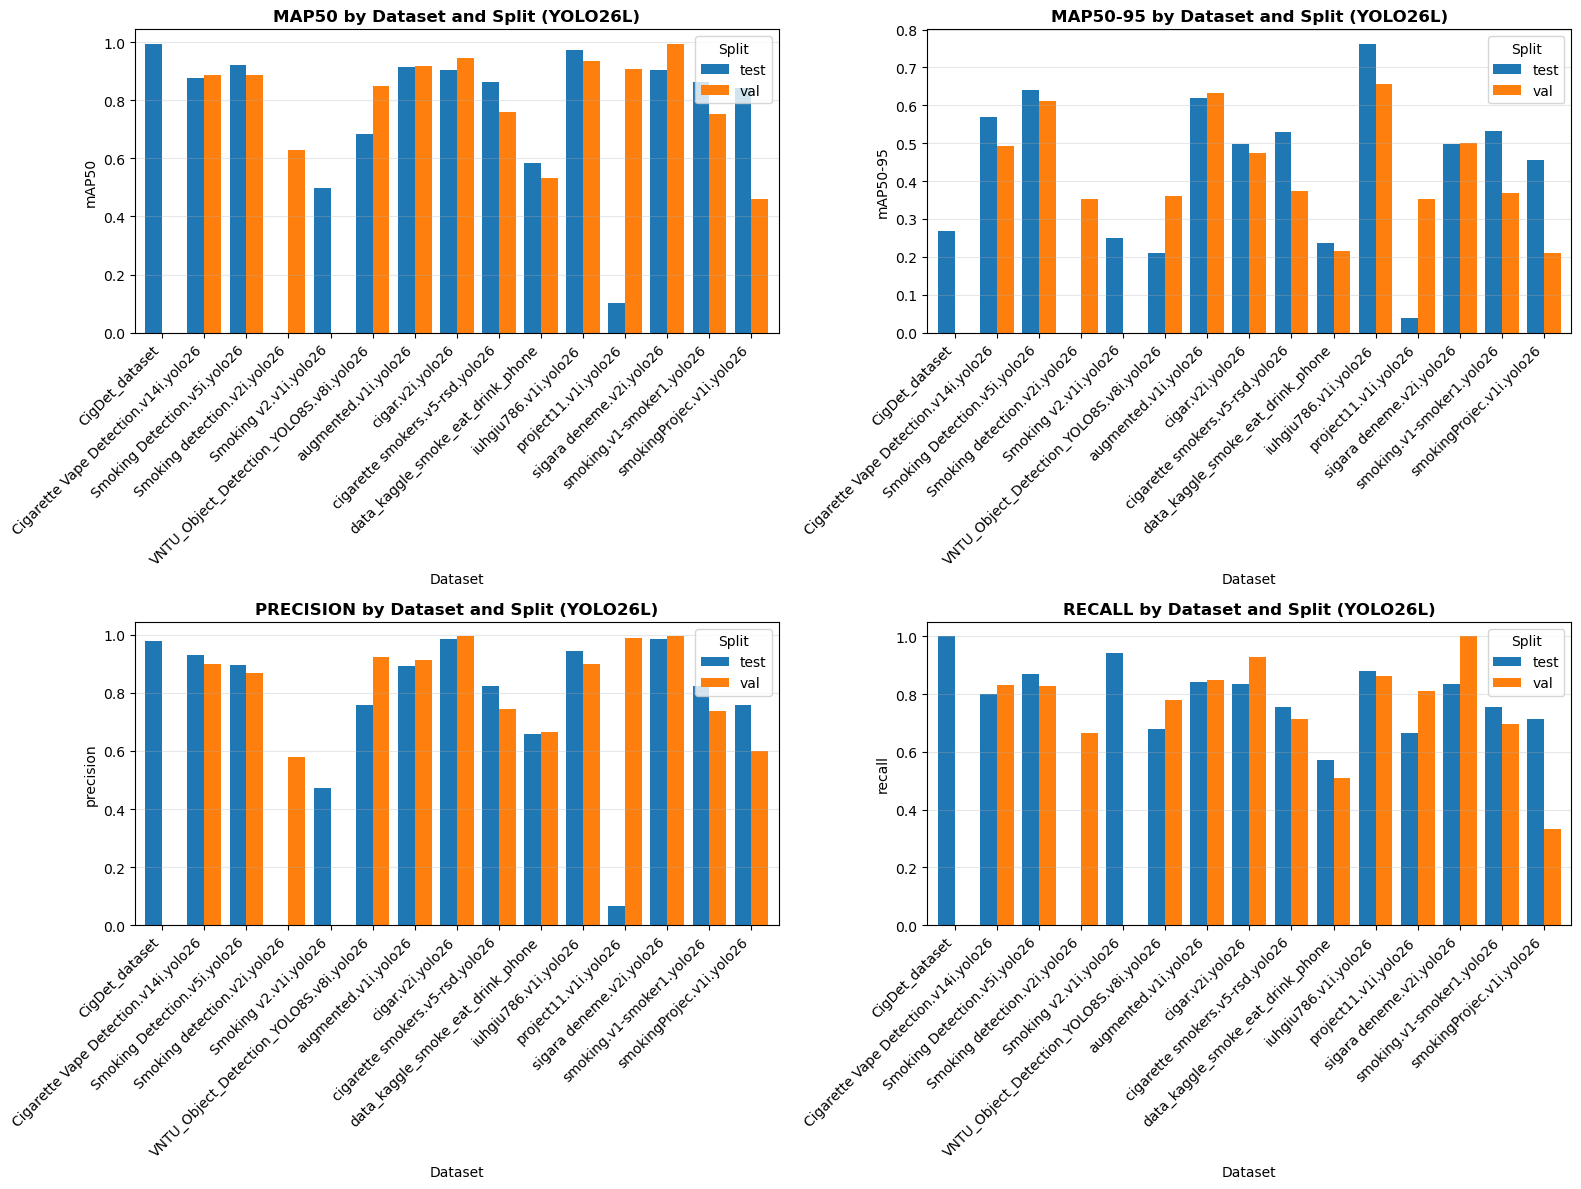

In [35]:
import seaborn as sns

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

for idx, metric in enumerate(['mAP50', 'mAP50-95', 'precision', 'recall']):
    ax = axes[idx // 2, idx % 2]
    
    pivot_data = yolo_metrics_df.pivot(index='dataset', columns='split', values=metric)
    pivot_data.plot(kind='bar', ax=ax, width=0.8)
    
    ax.set_title(f'{metric.upper()} by Dataset and Split (YOLO26L)', fontsize=12, fontweight='bold')
    ax.set_xlabel('Dataset', fontsize=10)
    ax.set_ylabel(metric, fontsize=10)
    ax.legend(title='Split')
    ax.grid(axis='y', alpha=0.3)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')

plt.tight_layout()
plt.savefig('yolo26_per_dataset_metrics.png', dpi=150, bbox_inches='tight')
plt.show()

Metrics on key datasets | Dataset size


image 1/1 yolo_dataset/val/images/z2743671587432_8ab4516bc830cee51218c28b29122896_jpg.rf.1bcb22f1839fd87663318d1d81df89ed.jpg: 640x640 (no detections), 29.6ms
Speed: 2.0ms preprocess, 29.6ms inference, 0.5ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 yolo_dataset/val/images/58737425_2266960976912065_1679883879810334720_n_jpg.rf.b7395f78efc11c618403501739916a09.jpg: 640x640 1 smoking, 19.0ms
Speed: 1.9ms preprocess, 19.0ms inference, 0.5ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 yolo_dataset/val/images/smoking_smoke_b000184_jpg.rf.0804633d38f3d7fb19e53f1bc65577ff.jpg: 640x640 1 smoking, 20.0ms
Speed: 2.2ms preprocess, 20.0ms inference, 0.5ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 yolo_dataset/val/images/smoking_0183_jpg.rf.b1a539e427a4ebf6090296a8f1be634b.jpg: 640x640 1 smoking, 18.9ms
Speed: 1.9ms preprocess, 18.9ms inference, 0.5ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 yolo_dataset/val/images/smoking_smoke_b0

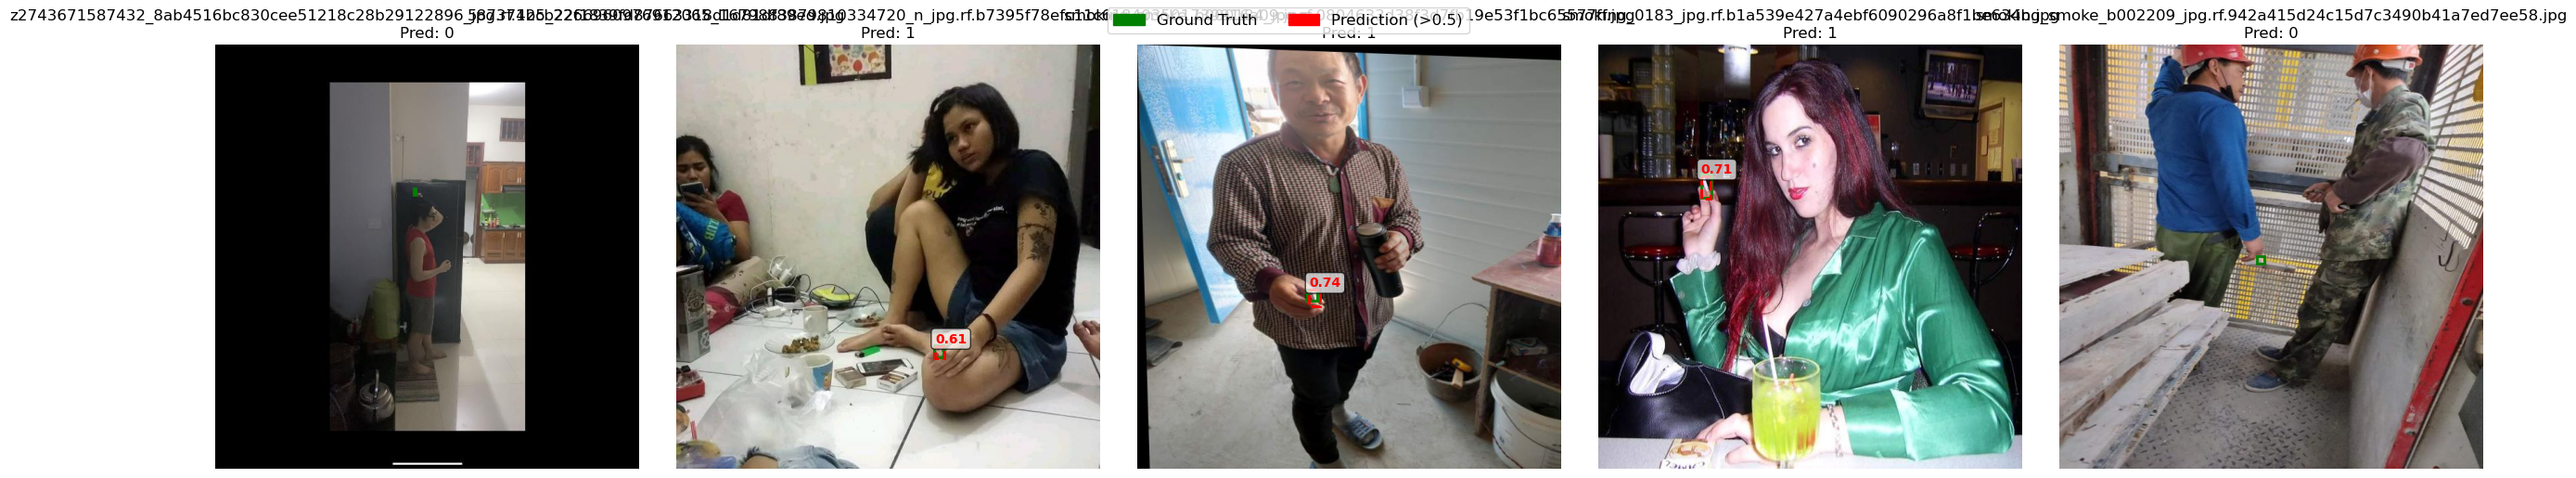

In [36]:
import random
import cv2

val_images = list((yolo_dir / 'val' / 'images').glob('*'))
random_images = random.sample(val_images, min(5, len(val_images)))

fig, axes = plt.subplots(1, 5, figsize=(25, 5))

for idx, img_path in enumerate(random_images):
    results = best_yolo.predict(str(img_path), conf=0.5, device=device)
    
    img = cv2.imread(str(img_path))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    
    label_path = yolo_dir / 'val' / 'labels' / f'{img_path.stem}.txt'
    
    ax = axes[idx]
    ax.imshow(img)
    
    if label_path.exists():
        h, w = img.shape[:2]
        with open(label_path, 'r') as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) >= 5:
                    _, x_center, y_center, width, height = map(float, parts[:5])
                    
                    x_min = int((x_center - width / 2) * w)
                    y_min = int((y_center - height / 2) * h)
                    box_w = int(width * w)
                    box_h = int(height * h)
                    
                    rect = patches.Rectangle((x_min, y_min), box_w, box_h,
                                             linewidth=2, edgecolor='green', facecolor='none')
                    ax.add_patch(rect)
    
    if len(results[0].boxes) > 0:
        boxes = results[0].boxes.xyxy.cpu().numpy()
        scores = results[0].boxes.conf.cpu().numpy()
        
        for box, score in zip(boxes, scores):
            x_min, y_min, x_max, y_max = box
            rect = patches.Rectangle((x_min, y_min), x_max - x_min, y_max - y_min,
                                     linewidth=2, edgecolor='red', facecolor='none', linestyle='--')
            ax.add_patch(rect)
            ax.text(x_min, y_min - 5, f'{score:.2f}', 
                   color='red', fontsize=10, weight='bold',
                   bbox=dict(boxstyle='round', facecolor='white', alpha=0.7))
    
    ax.set_title(f'{img_path.name}\nPred: {len(results[0].boxes)}')
    ax.axis('off')

green_patch = patches.Patch(color='green', label='Ground Truth')
red_patch = patches.Patch(color='red', label='Prediction (>0.5)')
fig.legend(handles=[green_patch, red_patch], loc='upper center', ncol=2, fontsize=12)

plt.tight_layout()
plt.savefig('yolo26_predictions_validation.png', dpi=150, bbox_inches='tight')
plt.show()